# Mappe delle testate e stile di scrittura

**La domanda**: le testate molto affidabili scrivono in modo diverso da quelle poco affidabili? Non solo di che cosa
parlano, ma **come** scrivono: frasi più articolate, più ragionamento, più fonti, meno enfasi.

Come nella tolerant accuracy, guardiamo i livelli **a finestre di due livelli vicini** (l1–l2, l2–l3, l3–l4, l4–l5)
e il **punteggio continuo** (0–100), invece dei livelli secchi. Rappresentiamo ogni testata in tre modi:

1. **parole** (TF-IDF, come nel notebook 1): che cosa dice la testata, argomenti compresi;
2. **stile profondo**: circa 30 misure di leggibilità, sintassi, ragionamento, fonti e tono, calcolate con spaCy;
3. **testo senza argomento** (*text distortion*, Stamatatos 2017): restano le parole funzionali e la punteggiatura,
   ogni altra parola diventa la sua categoria grammaticale. *"The senator, however, argued that the bill may fail"*
   diventa *"the PROPN , however , VERB that the NOUN may VERB"*: l'argomento sparisce, la costruzione delle frasi resta.

Per ognuna: mappe con quattro metodi, quanto si somigliano le testate vicine, classificatori sugli stessi fold.

In [1]:
T14_DIR = "../14_DatasetRipensatoChunk"      # dataset e fold del tentativo 14
LESSICI_DIR = "Dataset/lessici"              # lessici NRC (dal tentativo 13)
N_JOBS = 32                                   # processi in parallelo
PROVA = 0                                     # 0 = tutto; un numero = solo quei primi articoli per testata (prova veloce)

In [2]:
# Parameters
T14_DIR = "/home/fabio.pinelli/John/Tentativo14"


In [3]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap
from scipy.sparse import csr_matrix
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import MDS, TSNE, Isomap
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler, normalize
import sys

T14 = Path(T14_DIR).expanduser()
sys.path.insert(0, str(T14))
import funzioni as F                                  # funzioni del tentativo 14 (TF-IDF, metriche)
import stile as S                                     # misure di stile e testo senza argomento (in questa cartella)

warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"     # anche nei processi in parallelo
OUT = Path("Results") / ("prova" if PROVA else "")
GRAFICI = OUT / "grafici_mappe"; GRAFICI.mkdir(parents=True, exist_ok=True)
CACHE = OUT / "cache"; CACHE.mkdir(parents=True, exist_ok=True)

BLU, ARANCIO, VERDE, GRIGIO, CHIARO = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#b5b3ab"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
SCALA = LinearSegmentedColormap.from_list("punteggio", ["#b02a2a", "#ef8f8d", "#e1e0d9", "#86b6ef", "#1c5cab"])
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", ["#b02a2a", "#f0efec", "#1c5cab"])
plt.rcParams.update({
    "figure.figsize": (8, 3), "figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "legend.frameon": False,
})
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120); pd.set_option("display.max_rows", 60)

## 1. Il dataset e le finestre di livelli

In [4]:
# 1.1 articoli e testate del tentativo 14; le finestre sono coppie di livelli vicini (come nella tolerant accuracy)
art = pd.read_csv(T14 / "Results/dataset/articoli.csv.gz")
t = pd.read_csv(T14 / "Results/dataset/testate.csv", index_col="domain")
if PROVA:
    art = art.groupby("domain").head(PROVA).reset_index(drop=True)
FINESTRE = {"l1–l2": [0, 1], "l2–l3": [1, 2], "l3–l4": [2, 3], "l4–l5": [3, 4]}
print(f"{len(art):,} articoli di {len(t)} testate")
pd.DataFrame({f: {"punteggio": f"{t.score[t.label.isin(l)].min():.0f}–{t.score[t.label.isin(l)].max():.0f}",
                  "testate": int(t.label.isin(l).sum())} for f, l in FINESTRE.items()}).T

42,219 articoli di 323 testate


,punteggio,testate
l1–l2,0–58,147
l2–l3,40–72,129
l3–l4,60–95,134
l4–l5,75–100,140


## 2. L'analisi linguistica di ogni articolo

spaCy analizza ogni articolo (frasi, categorie grammaticali, struttura sintattica, entità). Da qui vengono le misure
di stile e il testo senza argomento. È la parte lunga: il risultato si salva e, se c'è già, si ricarica.

In [5]:
# 2.1 misure di stile e testo senza argomento per ogni articolo (in parallelo; i primi 3000 parole di ogni articolo)
f = CACHE / "stile_articoli.csv.gz"
if f.exists():
    st = pd.read_csv(f)
else:
    blocchi = np.array_split(np.arange(len(art)), N_JOBS * 4)
    ris = Parallel(n_jobs=N_JOBS)(delayed(S.analizza_blocco)(art.text.iloc[b].tolist(), LESSICI_DIR) for b in blocchi)
    st = pd.DataFrame([r for righe, _ in ris for r in righe])
    st["distorto"] = [d for _, ds in ris for d in ds]
    st.insert(0, "article_id", art.article_id.to_numpy()); st.insert(1, "domain", art.domain.to_numpy())
    st.to_csv(f, index=False)
assert (st.article_id.to_numpy() == art.article_id.to_numpy()).all()
MISURE = [c for c in st.columns if c not in ("article_id", "domain", "distorto")]
print(f"{len(st):,} articoli analizzati, {len(MISURE)} misure di stile")

42,219 articoli analizzati, 35 misure di stile


In [6]:
# 2.2 un esempio: lo stesso inizio di articolo, normale e senza argomento
i = art.index[art.domain == t.index[t.label == 4][0]][0]
print("NORMALE:          ", " ".join(art.text[i].split()[:45]), "…\n")
print("SENZA ARGOMENTO:  ", " ".join(st.distorto[i].split()[:50]), "…")

NORMALE:           As the November midterm elections approach, the Trump administration continues to push unsubstantiated claims about widespread noncitizen voting using flimsy evidence primarily based on half-baked list-matching efforts. In fact, a whistleblower has revealed that the U.S. Department of Homeland Security’s (DHS) actions likely violate state …

SENZA ARGOMENTO:   as the PROPN NOUN NOUN NOUN , the PROPN NOUN VERB to VERB ADJ NOUN about ADJ NOUN VERB using ADJ NOUN ADV VERB on ADJ - VERB NOUN - VERB NOUN . in NOUN , a NOUN has VERB that the PROPN PROPN of PROPN PROPN ’s ( PROPN …


## 3. Quali tratti di stile cambiano tra le testate poco e molto affidabili

Per ogni testata la **media** delle misure sui suoi articoli. Confrontiamo le testate **l1–l2** con le **l4–l5**
(le due finestre agli estremi) con il **delta di Cliff**: va da −1 a +1; positivo = più alto nelle affidabili;
sopra 0,33 in valore assoluto è un effetto medio, sopra 0,47 grande. Lo stesso confronto **dentro la destra e dentro
la sinistra**, per vedere se è stile o solo schieramento.

In [7]:
# 3.1 la media di ogni misura per testata e il confronto tra estremi
pt = st[MISURE].groupby(st.domain).mean().reindex(t.index)
basse, alte = (t.label <= 1).to_numpy(), (t.label >= 3).to_numpy()

def cliff(alto, basso):
    """Delta di Cliff: probabilità che una testata del primo gruppo abbia un valore più alto, meno il contrario."""
    a, b = alto.dropna(), basso.dropna()
    return 2 * mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1 if len(a) and len(b) else np.nan

righe = []
for m in MISURE:
    r = {"misura": m, **pt[m].groupby(t.livello).mean().round(2).to_dict()}
    r["delta l4–l5 vs l1–l2"] = cliff(pt[m][alte], pt[m][basse])
    r["p"] = mannwhitneyu(pt[m][alte].dropna(), pt[m][basse].dropna()).pvalue
    for o in ["Right", "Left"]:
        dentro = (t.orientamento == o).to_numpy()
        r[f"delta dentro {o}"] = cliff(pt[m][alte & dentro], pt[m][basse & dentro])
    righe.append(r)
tratti = pd.DataFrame(righe).set_index("misura").sort_values("delta l4–l5 vs l1–l2", key=abs, ascending=False)
tratti.to_csv(OUT / "tratti_di_stile.csv")
tratti.assign(p=tratti.p.map("{:.0e}".format)).round(2)

,l1,l2,l3,l4,l5,delta l4–l5 vs l1–l2,p,delta dentro Right,delta dentro Left
misura,,,,,,,,,
connettivi avversativi (‰),3.61,3.23,3.77,4.22,4.50,0.44,2e-10,0.25,0.60
parole emotive (‰),99.23,99.73,96.68,92.13,91.91,-0.40,7e-09,-0.39,0.04
"cautela, hedge (‰)",13.23,12.78,13.49,14.66,14.93,0.37,4e-08,0.22,0.63
avverbi (%),3.98,3.61,3.93,4.21,3.98,0.33,1e-06,0.24,0.74
superlativi (‰),2.52,2.50,2.77,2.90,2.91,0.32,4e-06,0.49,0.05
attribuzione alle fonti (‰),15.35,17.56,14.94,13.79,15.36,-0.30,1e-05,-0.40,-0.42
verbi (%),13.29,13.40,13.16,12.90,12.71,-0.29,2e-05,-0.39,0.02
io / noi (‰),10.63,8.58,10.93,13.03,10.34,0.29,2e-05,0.10,0.52
"parole lunghe, 7+ lettere (%)",28.80,28.39,28.08,26.90,27.90,-0.25,2e-04,-0.07,-0.28


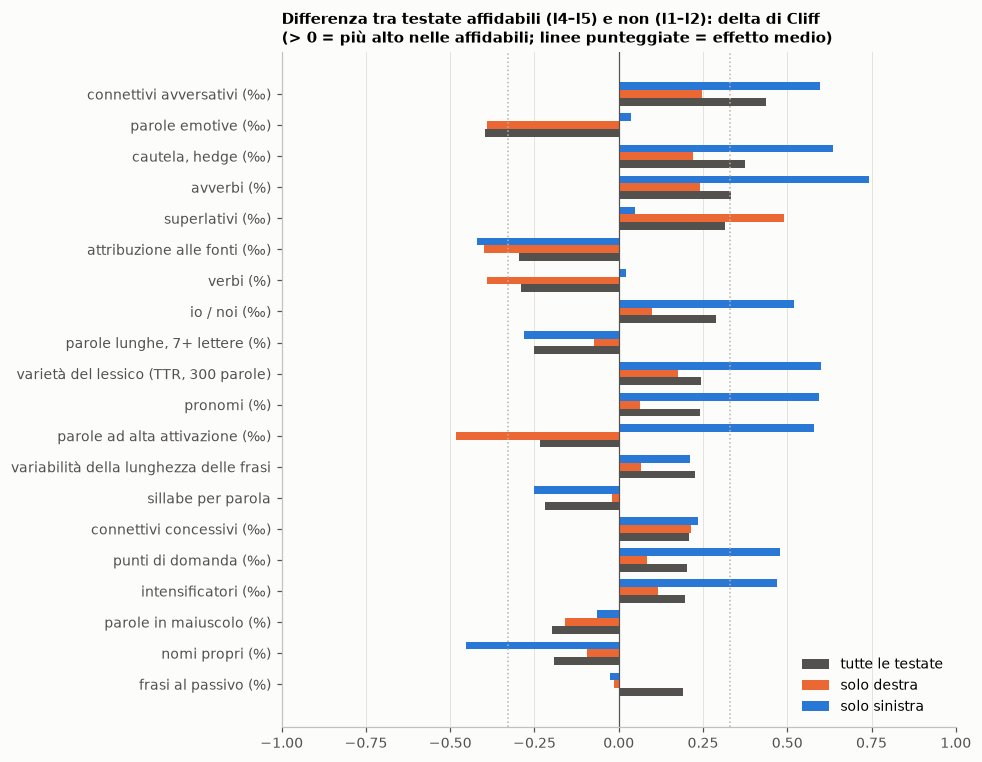

In [8]:
# 3.2 lo stesso in un grafico: delta tra estremi, in tutto il dataset e dentro ogni orientamento
top = tratti.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(top))
for dx, (col, colore, nome) in zip([-0.25, 0, 0.25], [("delta l4–l5 vs l1–l2", GRIGIO, "tutte le testate"),
                                                       ("delta dentro Right", ARANCIO, "solo destra"),
                                                       ("delta dentro Left", BLU, "solo sinistra")]):
    ax.barh(y + dx, top[col], height=0.25, color=colore, label=nome)
ax.set_yticks(y, top.index); ax.axvline(0, color=GRIGIO, lw=0.8)
for v in [-0.33, 0.33]:
    ax.axvline(v, color=CHIARO, ls=":", lw=1)
ax.set_xlim(-1, 1); ax.grid(False); ax.grid(axis="x")
ax.set_title("Differenza tra testate affidabili (l4–l5) e non (l1–l2): delta di Cliff\n(> 0 = più alto nelle affidabili; linee punteggiate = effetto medio)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(GRAFICI / "3_tratti.png", dpi=200, bbox_inches="tight"); plt.show()

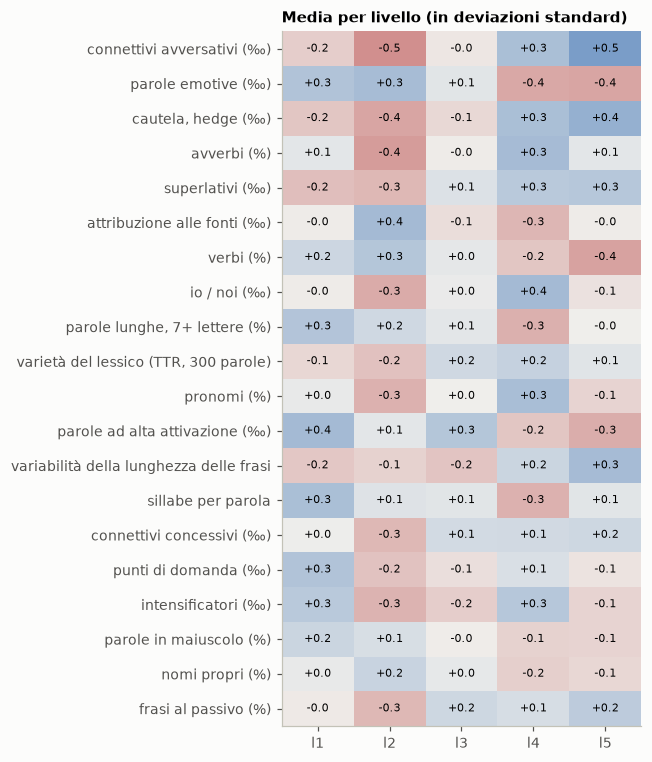

In [9]:
# 3.3 l'andamento per livello delle misure con l'effetto più grande (z-score delle medie per livello)
z = pt[tratti.index[:20]].groupby(t.livello).mean()
z = (z - pt[tratti.index[:20]].mean()) / pt[tratti.index[:20]].std()
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(z.T, cmap=DIVERGENTE, vmin=-1, vmax=1, aspect="auto"); ax.grid(False)
for i in range(z.shape[1]):
    for j in range(5):
        ax.text(j, i, f"{z.iloc[j, i]:+.1f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(5), F.LIVELLI); ax.set_yticks(range(z.shape[1]), z.columns)
ax.set_title("Media per livello (in deviazioni standard)")
plt.tight_layout(); plt.savefig(GRAFICI / "3_andamento.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Le mappe

Le tre rappresentazioni di ogni testata, ridotte a due dimensioni con quattro metodi che **non guardano le
etichette**: PCA (lineare), t-SNE (tiene vicini i vicini), Isomap (segue la forma dei dati), MDS (rispetta le
distanze). Prima colonna: il punteggio NewsGuard (rosso basso → blu alto); poi una finestra di livelli alla volta.

In [10]:
# 4.1 le tre rappresentazioni: una riga per testata
M = csr_matrix((np.ones(len(art)), (pd.Index(t.index).get_indexer(art.domain), np.arange(len(art)))), shape=(len(t), len(art)))
media_testata = lambda X: normalize(M @ X)                      # vettore medio dei suoi articoli
vettori_distorti = lambda: TfidfVectorizer(ngram_range=(1, 3), min_df=5, max_df=0.95, sublinear_tf=True, max_features=50_000,
                                           token_pattern=r"\S+", lowercase=False)
R = {"parole": media_testata(F._tfidf().fit_transform(art.text)),
     "stile profondo": StandardScaler().fit_transform(pt.fillna(pt.median())),
     "testo senza argomento": media_testata(vettori_distorti().fit_transform(st.distorto))}
for k, X in R.items():
    print(f"{k}: {X.shape[1]:,} dimensioni")

parole: 100,000 dimensioni
stile profondo: 35 dimensioni
testo senza argomento: 50,000 dimensioni


In [11]:
# 4.2 le coordinate 2D con i quattro metodi
def coordinate(X):
    Z = TruncatedSVD(50, random_state=0).fit_transform(X) if X.shape[1] > 50 else np.asarray(X)
    return {"PCA": PCA(2, random_state=0).fit_transform(Z),
            "t-SNE": TSNE(2, perplexity=25, init="pca", random_state=0).fit_transform(Z),
            "Isomap": Isomap(n_neighbors=10, n_components=2).fit_transform(Z),
            "MDS": MDS(2, random_state=0, n_init=1, normalized_stress="auto").fit_transform(Z)}

def disegna(nome, coord):
    fig, assi = plt.subplots(len(coord), 5, figsize=(17, 3.2 * len(coord)))
    for r, (metodo, P) in enumerate(coord.items()):
        assi[r, 0].scatter(P[:, 0], P[:, 1], c=t.score, cmap=SCALA, vmin=0, vmax=100, s=14, edgecolor="none")
        assi[r, 0].set_ylabel(metodo, fontsize=10, color=GRIGIO)
        for c, (fin, livelli) in enumerate(FINESTRE.items(), 1):
            dentro = t.label.isin(livelli).to_numpy()
            assi[r, c].scatter(P[~dentro, 0], P[~dentro, 1], s=7, color="#e1e0d9")
            for k in livelli:
                m = (t.label == k).to_numpy()
                assi[r, c].scatter(P[m, 0], P[m, 1], s=15, color=COLORE_LIVELLO[k], label=F.LIVELLI[k])
            if r == 0:
                assi[r, c].set_title(f"finestra {fin}"); assi[r, c].legend(fontsize=7, loc="best")
    assi[0, 0].set_title("punteggio (rosso basso → blu alto)")
    for a in assi.flat:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.suptitle(f"Mappa delle testate: {nome}", fontsize=12, fontweight="bold", x=0.01, ha="left")
    plt.tight_layout(); plt.savefig(GRAFICI / f"4_mappa_{nome.replace(' ', '_')}.png", dpi=170, bbox_inches="tight"); plt.show()

COORD = {k: coordinate(X) for k, X in R.items()}

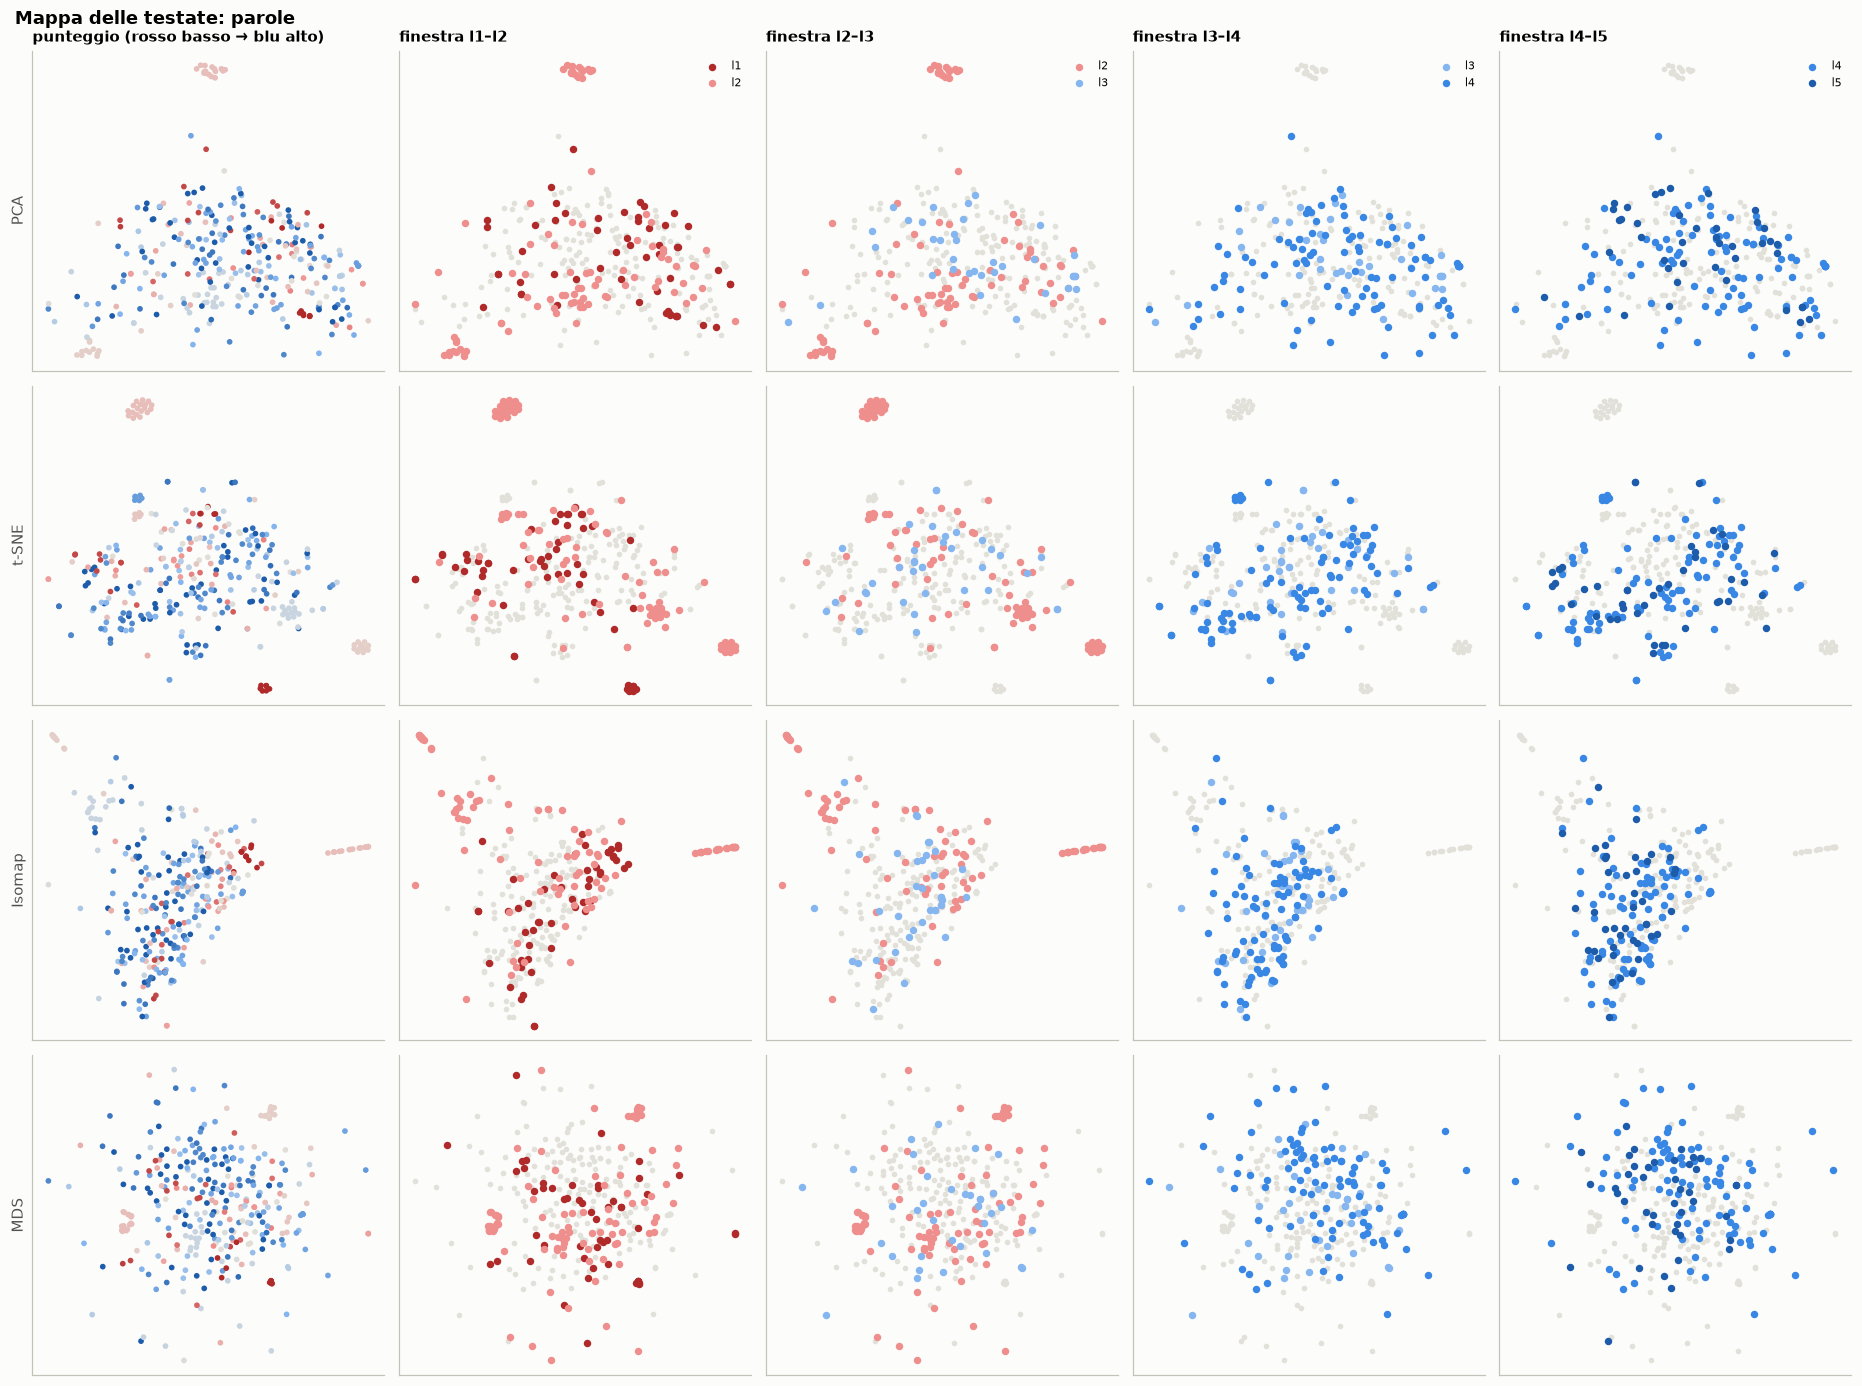

In [12]:
disegna("parole", COORD["parole"])

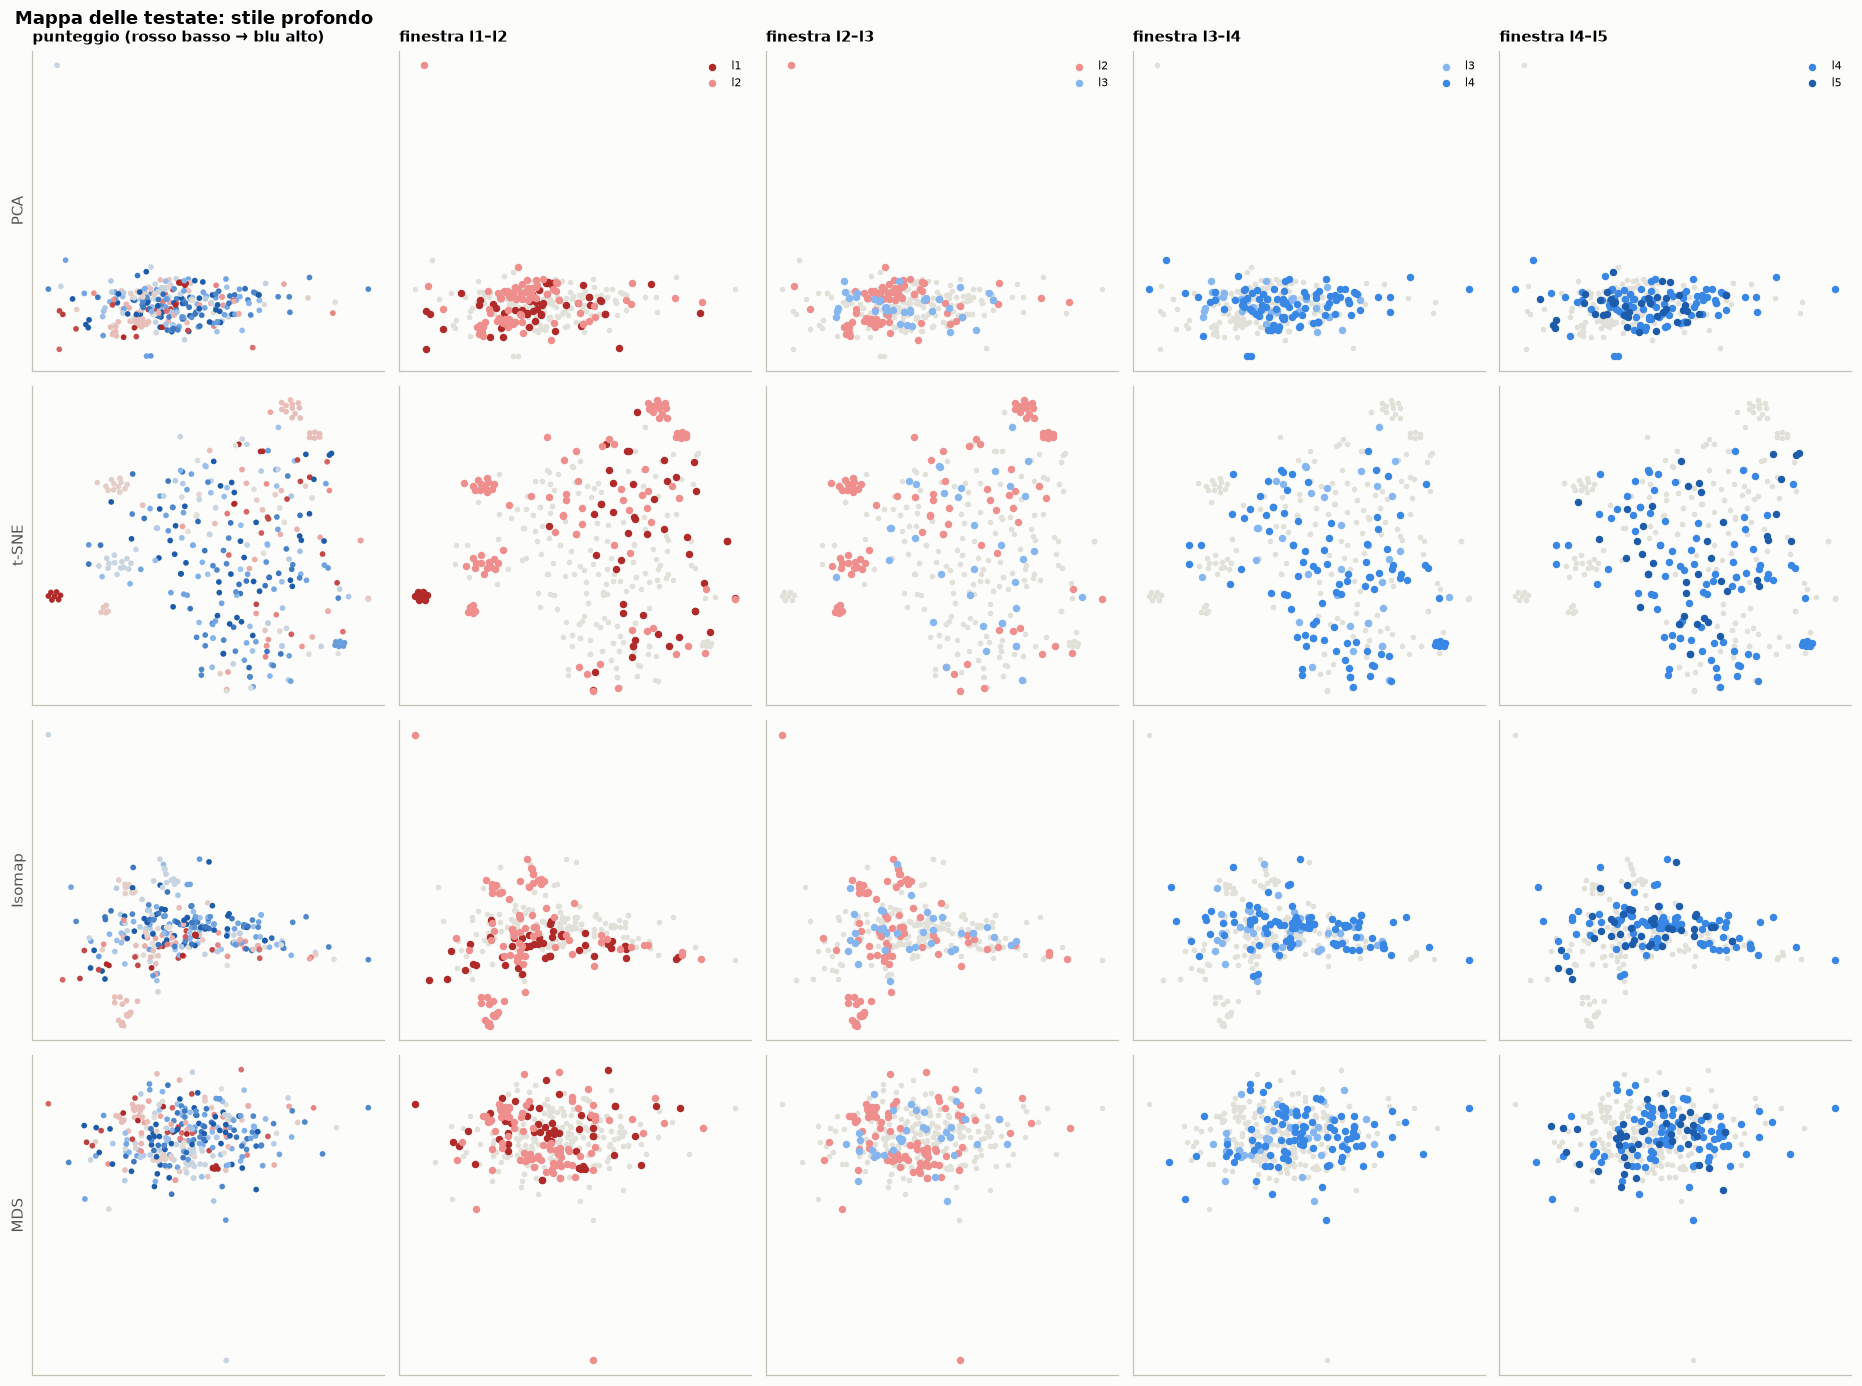

In [13]:
disegna("stile profondo", COORD["stile profondo"])

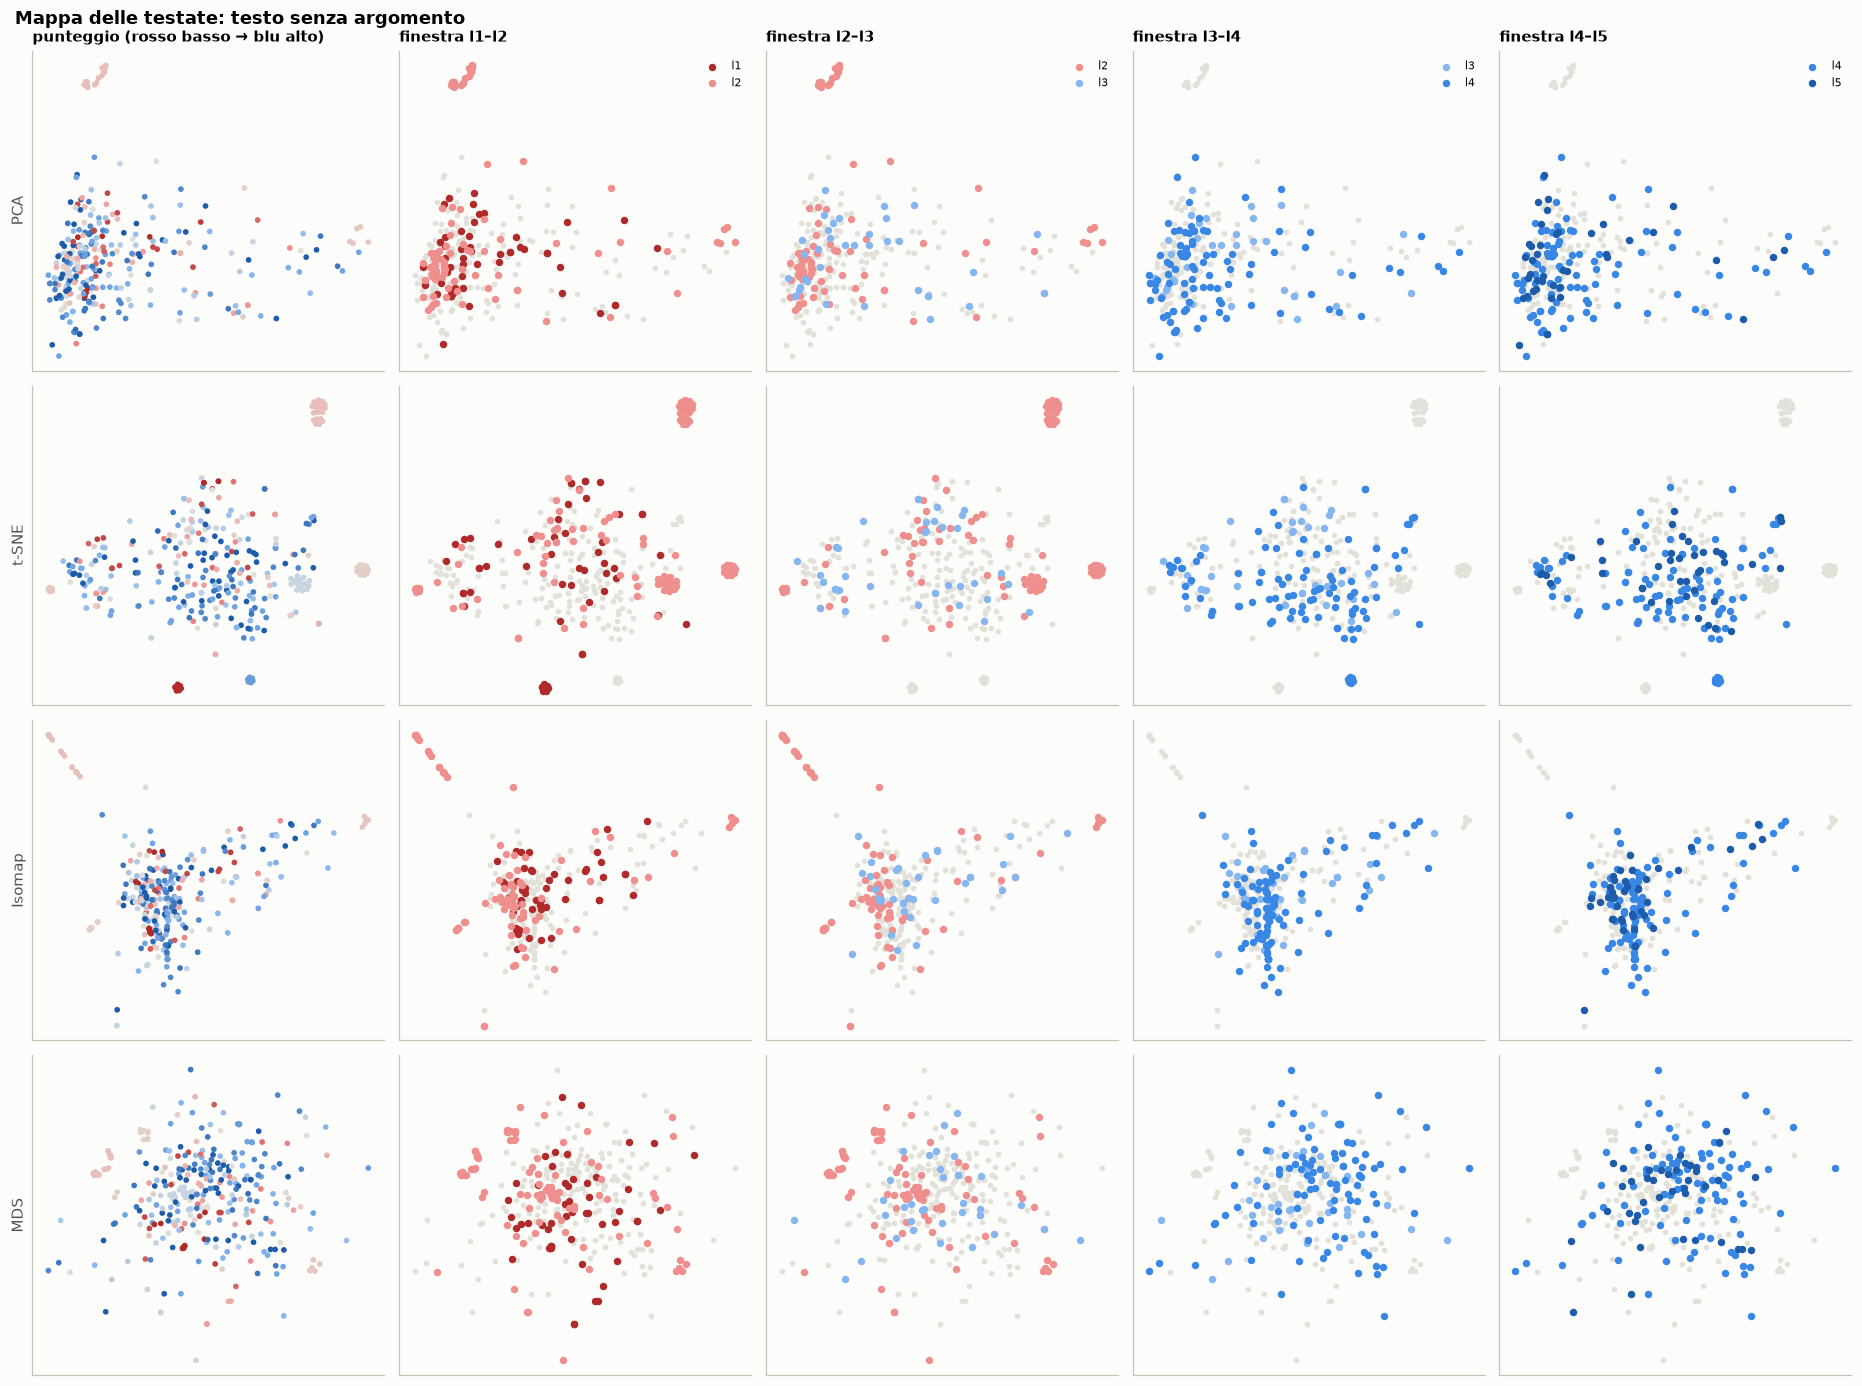

In [14]:
disegna("testo senza argomento", COORD["testo senza argomento"])

## 5. Le testate vicine si somigliano?

Un numero per ogni mappa, senza addestrare nulla. Per ogni testata prendiamo le 10 testate **più simili** (nello spazio
completo, non nella mappa), escluse quelle del suo stesso gruppo (che si somigliano per costruzione):

- **vicini nella stessa finestra**: quota di vicini che stanno al più a un livello di distanza (come la tolerant);
- **correlazione dei punteggi**: tra il punteggio della testata e la media dei punteggi dei suoi vicini.

Accanto, gli stessi numeri con **vicini presi a caso**: se una rappresentazione non sa nulla dell'affidabilità, fa
come il caso.

In [15]:
# 5.1 coerenza dei vicini, contro vicini presi a caso
gruppo = t.gruppo.to_numpy(); lab = t.label.to_numpy(); sc = t.score.to_numpy()
stesso = gruppo[:, None] == gruppo[None, :]

def coerenza(idx):
    return (np.abs(lab[idx] - lab[:, None]) <= 1).mean(), spearmanr(sc, sc[idx].mean(1)).correlation

rng = np.random.default_rng(0)
a_caso = np.array([coerenza(np.array([rng.choice(np.where(~stesso[i])[0], 10, replace=False) for i in range(len(t))]))
                   for _ in range(50)]).mean(0)
righe = [{"rappresentazione": "vicini a caso", "vicini nella stessa finestra": a_caso[0], "correlazione dei punteggi": a_caso[1]}]
for k, X in R.items():
    Ssim = cosine_similarity(X); Ssim[stesso] = -np.inf
    tol, cor = coerenza(np.argsort(-Ssim, axis=1)[:, :10])
    righe.append({"rappresentazione": k, "vicini nella stessa finestra": tol, "correlazione dei punteggi": cor})
pd.DataFrame(righe).set_index("rappresentazione").round(3)

,vicini nella stessa finestra,correlazione dei punteggi
rappresentazione,,
vicini a caso,0.534,-0.030
parole,0.600,0.350
stile profondo,0.620,0.370
testo senza argomento,0.611,0.415


## 6. I classificatori

Stessi 5 fold del tentativo 14 (un gruppo in un solo fold); per parole e testo senza argomento il TF-IDF si impara a
ogni fold sui soli articoli di training. Oltre ai 5 livelli, le domande "a finestre":

- **estremi**: l1–l2 contro l4–l5 (le testate l3 restano fuori), in tutto il dataset e dentro ogni orientamento;
- **vicini al confine**: l2 contro l3.

AUC: 0,5 = come a caso, 1 = separazione perfetta.

In [16]:
# 6.1 le rappresentazioni per fold (vocabolario e pesi TF-IDF dai soli articoli di training)
def del_fold(k):
    tr = (art.fold != k).to_numpy()
    parole = media_testata(F._tfidf().fit(art.text[tr]).transform(art.text))
    distorto = media_testata(vettori_distorti().fit(st.distorto[tr]).transform(st.distorto))
    return k, {"parole": parole, "testo senza argomento": distorto}

PER_FOLD = dict(Parallel(n_jobs=min(5, N_JOBS))(delayed(del_fold)(k) for k in range(1, 6)))
for k in PER_FOLD:
    PER_FOLD[k]["stile profondo"] = pt.fillna(pt.median()).to_numpy()
C = {"parole": 10, "testo senza argomento": 10, "stile profondo": 1}
print("fatto")

fatto


In [17]:
# 6.2 probabilità fuori fold, per i 5 livelli e per le domande a finestre
def fuori_fold(nome, dentro=None, positivi=None):
    """Probabilità fuori fold. Senza `positivi`: i 5 livelli. Con `positivi`: un classificatore binario sulle sole testate `dentro`."""
    P = np.full((len(t), 5 if positivi is None else 1), np.nan)
    dentro = np.ones(len(t), bool) if dentro is None else dentro
    y = lab if positivi is None else np.isin(lab, positivi)
    for k in range(1, 6):
        tr, te = dentro & (t.fold != k).to_numpy(), dentro & (t.fold == k).to_numpy()
        if not te.any() or len(set(y[tr])) < 2:
            continue
        X = PER_FOLD[k][nome]
        if nome == "stile profondo":
            sc_ = StandardScaler().fit(X[tr]); X = sc_.transform(X)
        clf = LogisticRegression(C=C[nome], max_iter=5000, class_weight="balanced").fit(X[tr], y[tr])
        p = clf.predict_proba(X[te])
        P[te] = p if positivi is None else p[:, [1]]
    return P

def auc(P, dentro, positivi):
    ok = dentro & ~np.isnan(P[:, 0])
    return roc_auc_score(np.isin(lab[ok], positivi), P[ok, 0])

estremi = np.isin(lab, [0, 1, 3, 4]); confine = np.isin(lab, [1, 2])
destra, sinistra = (t.orientamento == "Right").to_numpy(), (t.orientamento == "Left").to_numpy()
NOMI = ["parole", "stile profondo", "testo senza argomento"]
P5 = {n: fuori_fold(n) for n in NOMI}
P5["stile + testo senza argomento"] = (P5["stile profondo"] + P5["testo senza argomento"]) / 2     # media delle probabilità

righe = []
for n in NOMI + ["stile + testo senza argomento"]:
    parti = [n] if n in NOMI else ["stile profondo", "testo senza argomento"]
    finestra = lambda dentro, pos: np.mean([fuori_fold(p, dentro, pos) for p in parti], axis=0)
    righe.append({"rappresentazione": n,
                  "AUC estremi (l1–l2 / l4–l5)": auc(finestra(estremi, [3, 4]), estremi, [3, 4]),
                  "AUC estremi, solo destra": auc(finestra(estremi & destra, [3, 4]), estremi & destra, [3, 4]),
                  "AUC estremi, solo sinistra": auc(finestra(estremi & sinistra, [3, 4]), estremi & sinistra, [3, 4]),
                  "AUC l2 / l3": auc(finestra(confine, [2]), confine, [2])})
finestre = pd.DataFrame(righe).set_index("rappresentazione")
finestre.to_csv(OUT / "auc_finestre.csv")
finestre.round(3)

,AUC estremi (l1–l2 / l4–l5),"AUC estremi, solo destra","AUC estremi, solo sinistra",AUC l2 / l3
rappresentazione,,,,
parole,0.786,0.686,0.725,0.524
stile profondo,0.691,0.587,0.725,0.550
testo senza argomento,0.751,0.566,0.743,0.476
stile + testo senza argomento,0.728,0.596,0.754,0.534


In [18]:
# 6.3 i 5 livelli: F1, tolerant ±1 e binario, con intervalli da bootstrap per gruppo
prev = {n: P.argmax(1) for n, P in P5.items()}
cinque = F.confronto(t.label, t.gruppo, prev, riferimenti=["parole"])
cinque.to_csv(OUT / "cinque_livelli.csv")
cinque[["F1 macro", "F1 macro IC", "tolerant ±1", "tolerant ±1 IC", "binario", "ΔF1 vs parole"]].round(3)

,F1 macro,F1 macro IC,tolerant ±1,tolerant ±1 IC,binario,ΔF1 vs parole
modello,,,,,,
parole,0.382,[0.308; 0.445],0.706,[0.634; 0.776],0.632,NaN
stile profondo,0.252,[0.190; 0.311],0.663,[0.600; 0.728],0.607,-0.130 [-0.212; -0.046]
testo senza argomento,0.274,[0.205; 0.340],0.675,[0.614; 0.739],0.588,-0.108 [-0.161; -0.050]
stile + testo senza argomento,0.282,[0.217; 0.345],0.663,[0.598; 0.731],0.601,-0.100 [-0.180; -0.016]


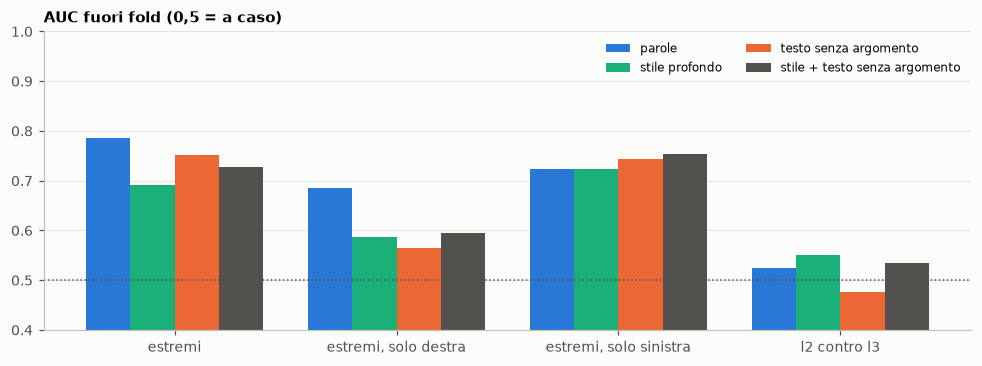

In [19]:
# 6.4 in un grafico: AUC sugli estremi e sul confine, per rappresentazione
fig, ax = plt.subplots(figsize=(9, 3.4))
colonne = ["AUC estremi (l1–l2 / l4–l5)", "AUC estremi, solo destra", "AUC estremi, solo sinistra", "AUC l2 / l3"]
x = np.arange(len(colonne)); w = 0.2
for i, (n, colore) in enumerate(zip(finestre.index, [BLU, VERDE, ARANCIO, GRIGIO])):
    ax.bar(x + (i - 1.5) * w, finestre.loc[n, colonne], width=w, color=colore, label=n)
ax.axhline(0.5, color=GRIGIO, ls=":", lw=1); ax.set_ylim(0.4, 1)
ax.set_xticks(x, ["estremi", "estremi, solo destra", "estremi, solo sinistra", "l2 contro l3"])
ax.set_title("AUC fuori fold (0,5 = a caso)"); ax.legend(fontsize=8, ncol=2, loc="upper right")
ax.grid(False); ax.grid(axis="y")
plt.tight_layout(); plt.savefig(GRAFICI / "6_auc.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Le costruzioni tipiche, senza argomento

Le sequenze di 2–4 elementi del testo senza argomento più tipiche delle testate l1–l2 e delle l4–l5 (log-odds con
prior informativo, Monroe et al. 2008; al più 30 articoli per testata, sequenze usate da almeno 10 testate). Teniamo
solo le sequenze con almeno una parola vera (come *but*, *of*, *that*, *I*): quelle di sole etichette dicono poco.
Si legge così: `according to PROPN` = "secondo" + un nome proprio.

In [20]:
# 7.1 log-odds delle sequenze tra le due finestre agli estremi
from sklearn.feature_extraction.text import CountVectorizer
campione = st.assign(label=art.label.to_numpy()).sample(frac=1, random_state=0).groupby("domain").head(30)
campione = campione[np.isin(campione.label, [0, 1, 3, 4])]
cv = CountVectorizer(ngram_range=(2, 4), token_pattern=r"\S+", lowercase=False, min_df=20)
X = cv.fit_transform(campione.distorto)
di_testata = csr_matrix((np.ones(len(campione)), (pd.factorize(campione.domain)[0], np.arange(len(campione)))))
nomi = cv.get_feature_names_out()
con_parola = np.array([any(p.isalpha() and p.islower() for p in g.split()) and not any(p in ("X", "SYM", "_") for p in g.split()) for g in nomi])
tenute = (np.asarray(((di_testata @ (X > 0).astype(np.int32)) > 0).sum(0)).ravel() >= 10) & con_parola
alto = (campione.label >= 3).to_numpy()
ca, cb = np.asarray(X[alto][:, tenute].sum(0)).ravel(), np.asarray(X[~alto][:, tenute].sum(0)).ravel()
prior = (ca + cb) * 0.01
dlt = np.log((ca + prior) / (ca.sum() + prior.sum() - ca - prior)) - np.log((cb + prior) / (cb.sum() + prior.sum() - cb - prior))
zz = pd.Series(dlt / np.sqrt(1 / (ca + prior) + 1 / (cb + prior)), index=nomi[tenute]).sort_values()
pd.DataFrame({"tipiche di l1–l2": zz.index[:25], "tipiche di l4–l5": zz.index[::-1][:25]})

,tipiche di l1–l2,tipiche di l4–l5
0,"NOUN , and",NOUN of
1,. that,the NOUN of
2,", and",i VERB
3,NOUN VERB the,. but
4,", and NOUN",PROPN i
5,the NOUN VERB,. i
6,. that NOUN,ADJ to
7,NOUN VERB the NOUN,of NOUN
8,NOUN say,PROPN PROPN i
9,"NOUN , and NOUN",NOUN . but


## 8. In breve

In [21]:
# 8.1 i numeri principali
print("tratti con effetto almeno medio tra estremi (|delta| >= 0,33):", ", ".join(tratti.index[tratti["delta l4–l5 vs l1–l2"].abs() >= 0.33]))
for n in finestre.index:
    print(f"- {n}: AUC estremi {finestre.loc[n, 'AUC estremi (l1–l2 / l4–l5)']:.2f} (destra {finestre.loc[n, 'AUC estremi, solo destra']:.2f}, "
          f"sinistra {finestre.loc[n, 'AUC estremi, solo sinistra']:.2f}); l2/l3 {finestre.loc[n, 'AUC l2 / l3']:.2f}; "
          f"F1 5 livelli {cinque.loc[n, 'F1 macro']:.3f}, tolerant {cinque.loc[n, 'tolerant ±1']:.3f}")

tratti con effetto almeno medio tra estremi (|delta| >= 0,33): connettivi avversativi (‰), parole emotive (‰), cautela, hedge (‰), avverbi (%)
- parole: AUC estremi 0.79 (destra 0.69, sinistra 0.72); l2/l3 0.52; F1 5 livelli 0.382, tolerant 0.706
- stile profondo: AUC estremi 0.69 (destra 0.59, sinistra 0.72); l2/l3 0.55; F1 5 livelli 0.252, tolerant 0.663
- testo senza argomento: AUC estremi 0.75 (destra 0.57, sinistra 0.74); l2/l3 0.48; F1 5 livelli 0.274, tolerant 0.675
- stile + testo senza argomento: AUC estremi 0.73 (destra 0.60, sinistra 0.75); l2/l3 0.53; F1 5 livelli 0.282, tolerant 0.663


## 9. Che cosa ne concludiamo

- **Uno stile delle testate affidabili c'è, ed è quello che ci si aspetta.** Rispetto alle l1–l2, le l4–l5 usano:
  - più connettivi avversativi (*however, whereas, but* a inizio frase), delta +0,44;
  - meno parole emotive (−0,40) e meno maiuscole e punti esclamativi;
  - più cautela (*may, likely, suggests*, +0,37);
  - più avverbi e un lessico più vario;
  - più costruzioni nominali articolate (*the NOUN of*, *a NOUN of*).

  Le l1–l2 invece riportano di più (*NOUN say*, attribuzioni) e costruiscono per accumulo (*, and*, *, not*).
- **Non è solo argomento.** Senza argomento (solo struttura delle frasi e parole funzionali):
  - le testate vicine hanno punteggi più simili che con le parole (correlazione 0,42 contro 0,35; a caso −0,03);
  - un classificatore separa gli estremi con AUC 0,75 (parole 0,79).
- **Dipende dallo schieramento.**
  - Dentro la sinistra gli effetti sono grandi: cautela +0,63, avverbi +0,74, varietà del lessico +0,60. Lo stile vale quanto le parole (AUC 0,72–0,75).
  - Dentro la destra lo stile distingue poco (AUC 0,57–0,60), e contano più le parole (0,69).
- **I livelli vicini non si distinguono.** l2 contro l3 è a caso con qualsiasi rappresentazione (0,48–0,55). Sui 5
  livelli lo stile da solo arriva a F1 0,25–0,28, le parole a 0,38.

**In una frase**: le testate molto affidabili scrivono in modo più ragionato, più prudente e meno emotivo, e questo
si vede anche togliendo l'argomento (AUC circa 0,75 sugli estremi). Ma è una differenza **di grado**: separa bene gli
estremi, soprattutto a sinistra, e quasi per nulla i livelli vicini al confine di affidabilità.